# Classification Track — Water Quality Classification
### 23CSE301 Machine Learning Capstone — Review 2 (Part B)

**Dataset:** Water-quality measurements (`data/classification/water_quality_classification_dataset.csv`)

**Objective:** Train and compare the five remaining classification algorithms required for Part B:
1. Random Forest Classifier
2. AdaBoost Classifier
3. Gradient Boosting Classifier
4. Bagging Classifier with a Decision Tree base estimator
5. MLP Classifier (neural network)

This notebook is organized into numbered sections with explanations, code, visual evaluation, model comparison, hyperparameter tuning, cross-validation, and final model selection.

**Methodology note:** The `Water_Quality_Class` labels are the project-defined target. Rows with missing target labels are excluded. Since the target is derived from water-quality measurements in this project, performance should be interpreted as agreement with that constructed label—not as independent proof of official water-safety status.

In [1]:
# 1. Imports
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, BaggingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "classification").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "classification" / "water_quality_classification_dataset.csv"

print("Imports completed.")


Imports completed.


The first step is to inspect the dataset before modeling. This checks the row/column count, target-label availability, class distribution, and exact duplicate rows.

## 2. Load and audit the dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing target:", df["Water_Quality_Class"].isna().sum())
print("\nTarget distribution:")
display(df["Water_Quality_Class"].value_counts(dropna=False))

print("\nExact duplicate rows:", df.duplicated().sum())


Dataset shape: (80000, 53)


,Sample Date,Sample Time,Depth,total_phosphorus,pH,temperature,dissolved_reactive_phosphorus,total_dissolved_phosphorus,electrical_conductance,nitrate_nitrogen,...,fluoride,strontium,lithium,sulfate,total_solids,ammonium_nitrogen,oxidized_nitrogen,nickel,ammonia_nitrogen,Water_Quality_Class
0,2016-04-01,12:00,0.3,0.809007,8.10,27.5,NaN,NaN,1613.0,9.679672,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0068,1.2597,Poor
1,2001-03-06,12:00,0.3,NaN,4.72,7.9,NaN,NaN,1003.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Poor
2,2019-01-24,NaN,14.0,NaN,NaN,24.7,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01,NaN,1.0,NaN,NaN,NaN,NaN,NaN,638.0,8.939066,...,NaN,NaN,NaN,NaN,NaN,0.007765,NaN,NaN,NaN,Moderate
4,2014-10-01,NaN,0.3,NaN,NaN,NaN,NaN,NaN,471.0,17.381518,...,NaN,NaN,NaN,NaN,NaN,0.007765,NaN,NaN,NaN,Moderate



Missing target: 12112

Target distribution:


Water_Quality_Class
Moderate    39550
Good        15651
Poor        12687
NaN         12112
Name: count, dtype: int64


Exact duplicate rows: 116


A supervised classifier needs a known target for every training example. Only rows with missing target labels are removed at this stage.

## 3. Target cleaning

Rows with a missing target cannot be used for supervised classification, so they are removed. Duplicate rows are reported but retained to stay consistent with the current Part-A workflow.


In [3]:
df_model = df.dropna(subset=["Water_Quality_Class"]).copy()

print("Rows before target filtering:", len(df))
print("Rows after target filtering:", len(df_model))
print("Rows removed:", len(df) - len(df_model))
print("Duplicates retained:", df_model.duplicated().sum())


Rows before target filtering: 80000
Rows after target filtering: 67888
Rows removed: 12112
Duplicates retained: 15


Date and time are converted into numeric components, and a solids-to-conductivity ratio is added. Raw date/time text is then removed because the models use numerical predictors.

## 4. Feature engineering

In [4]:
date_parsed = pd.to_datetime(df_model["Sample Date"], errors="coerce")
time_parsed = pd.to_datetime(df_model["Sample Time"], errors="coerce")

df_model["sample_year"] = date_parsed.dt.year
df_model["sample_month"] = date_parsed.dt.month
df_model["sample_dayofyear"] = date_parsed.dt.dayofyear
df_model["sample_hour"] = time_parsed.dt.hour
df_model["sample_minute"] = time_parsed.dt.minute

denominator = df_model["electrical_conductance"].replace(0, np.nan)
df_model["solids_conductivity_ratio"] = (
    df_model["total_solids"] / denominator
)

df_model = df_model.drop(columns=["Sample Date", "Sample Time"])

TARGET = "Water_Quality_Class"
X = df_model.drop(columns=[TARGET]).select_dtypes(include=np.number).copy()
y_text = df_model[TARGET].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("Predictor features:", X.shape[1])
print("Classes:", list(label_encoder.classes_))


Predictor features: 56
Classes: ['Good', 'Moderate', 'Poor']


Stratification preserves approximately the same class proportions in training and test sets. The identical split is reused across all five algorithms.

## 5. Stratified 80:20 train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (54310, 56)
Testing: (13578, 56)


Imputation, outlier clipping, and scaling are fitted inside the pipeline. This prevents the test set from influencing preprocessing parameters.

## 6. Leak-free preprocessing

Median imputation, IQR clipping, and standardization are placed inside the pipeline. Therefore, values learned during preprocessing come only from the relevant training data/fold.


In [6]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.q1_ = X_df.quantile(0.25)
        self.q3_ = X_df.quantile(0.75)
        self.iqr_ = self.q3_ - self.q1_
        self.lower_ = self.q1_ - 1.5 * self.iqr_
        self.upper_ = self.q3_ + 1.5 * self.iqr_
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X)
        return X_df.clip(self.lower_, self.upper_, axis=1).to_numpy()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("iqr_clipper", IQRClipper()),
    ("scaler", StandardScaler())
])

preprocessor = Pipeline([
    ("numeric", numeric_preprocessor)
])

print("Preprocessing pipeline ready.")


Preprocessing pipeline ready.


The shared evaluation function ensures every model is assessed with the same metrics and reporting format.

## 7. Evaluation function

In [7]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    }

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
        scores["ROC-AUC"] = roc_auc_score(
            y_test, y_score, multi_class="ovr", average="weighted"
        )
    else:
        scores["ROC-AUC"] = np.nan

    print("\n" + name)
    print("-" * len(name))
    for k, v in scores.items():
        if k != "Model":
            print(f"{k}: {v:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_test, y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    ))

    return model, scores, y_pred


Random Forest combines many decision trees. Random feature selection and bootstrap samples help reduce the variance of a single tree.

## 8. Random Forest Classifier

In [8]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model, rf_scores, rf_pred = evaluate_model(
    "Random Forest", rf_pipeline
)



Random Forest
-------------
Accuracy: 0.7953
Precision: 0.7939
Recall: 0.7953
Weighted F1: 0.7919
ROC-AUC: 0.9014

Classification report:
              precision    recall  f1-score   support

        Good       0.81      0.75      0.78      3130
    Moderate       0.80      0.87      0.84      7910
        Poor       0.75      0.61      0.67      2538

    accuracy                           0.80     13578
   macro avg       0.79      0.74      0.76     13578
weighted avg       0.79      0.80      0.79     13578



AdaBoost trains weak learners sequentially, increasing attention to observations that earlier learners classified incorrectly.

## 9. AdaBoost Classifier

In [9]:
ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

ada_model, ada_scores, ada_pred = evaluate_model(
    "AdaBoost", ada_pipeline
)



AdaBoost
--------
Accuracy: 0.6630
Precision: 0.6668
Recall: 0.6630
Weighted F1: 0.6383
ROC-AUC: 0.7672

Classification report:
              precision    recall  f1-score   support

        Good       0.74      0.39      0.51      3130
    Moderate       0.66      0.87      0.75      7910
        Poor       0.60      0.36      0.45      2538

    accuracy                           0.66     13578
   macro avg       0.67      0.54      0.57     13578
weighted avg       0.67      0.66      0.64     13578



Gradient Boosting adds trees sequentially to reduce errors left by the current ensemble.

## 10. Gradient Boosting Classifier

In [10]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

gb_model, gb_scores, gb_pred = evaluate_model(
    "Gradient Boosting", gb_pipeline
)



Gradient Boosting
-----------------
Accuracy: 0.7624
Precision: 0.7603
Recall: 0.7624
Weighted F1: 0.7593
ROC-AUC: 0.8808

Classification report:
              precision    recall  f1-score   support

        Good       0.77      0.70      0.74      3130
    Moderate       0.77      0.84      0.81      7910
        Poor       0.70      0.59      0.64      2538

    accuracy                           0.76     13578
   macro avg       0.75      0.71      0.73     13578
weighted avg       0.76      0.76      0.76     13578



Bagging trains multiple decision trees on bootstrap samples and combines their predictions. This can reduce the instability of a single tree.

## 11. Bagging Classifier — Decision Tree base

In [11]:
bag_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

bag_model, bag_scores, bag_pred = evaluate_model(
    "Bagging", bag_pipeline
)



Bagging
-------
Accuracy: 0.7903
Precision: 0.7883
Recall: 0.7903
Weighted F1: 0.7883
ROC-AUC: 0.8972

Classification report:
              precision    recall  f1-score   support

        Good       0.80      0.77      0.78      3130
    Moderate       0.81      0.85      0.83      7910
        Poor       0.72      0.63      0.67      2538

    accuracy                           0.79     13578
   macro avg       0.77      0.75      0.76     13578
weighted avg       0.79      0.79      0.79     13578



The Multi-Layer Perceptron is a feed-forward neural network. Scaling is important because its optimization is sensitive to differences in feature magnitude.

## 12. MLP Classifier

In [12]:
mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE
    ))
])

mlp_model, mlp_scores, mlp_pred = evaluate_model(
    "MLP", mlp_pipeline
)



MLP
---
Accuracy: 0.7604
Precision: 0.7587
Recall: 0.7604
Weighted F1: 0.7560
ROC-AUC: 0.8785

Classification report:
              precision    recall  f1-score   support

        Good       0.80      0.69      0.74      3130
    Moderate       0.77      0.85      0.81      7910
        Poor       0.69      0.56      0.62      2538

    accuracy                           0.76     13578
   macro avg       0.75      0.70      0.72     13578
weighted avg       0.76      0.76      0.76     13578



This table compares all five Part-B algorithms using the same held-out test set. Weighted F1 is useful when class proportions differ.

## 13. Part-B comparison table

In [13]:
partB_results = pd.DataFrame([
    rf_scores, ada_scores, gb_scores, bag_scores, mlp_scores
]).sort_values("Weighted F1", ascending=False).reset_index(drop=True)

display(partB_results.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "Weighted F1": "{:.4f}",
    "ROC-AUC": "{:.4f}"
}))


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Random Forest,0.7953,0.7939,0.7953,0.7919,0.9014
1,Bagging,0.7903,0.7883,0.7903,0.7883,0.8972
2,Gradient Boosting,0.7624,0.7603,0.7624,0.7593,0.8808
3,MLP,0.7604,0.7587,0.7604,0.7560,0.8785
4,AdaBoost,0.6630,0.6668,0.6630,0.6383,0.7672


Confusion matrices show which classes are correctly predicted and which pairs of classes are confused.

## 14. Confusion matrices

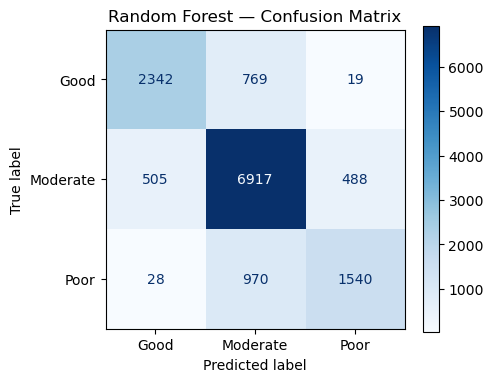

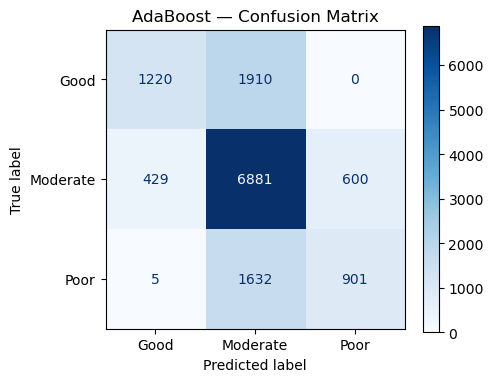

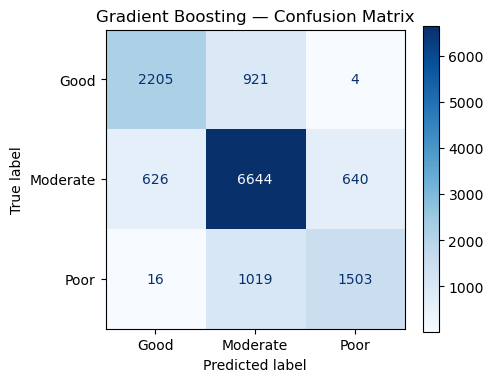

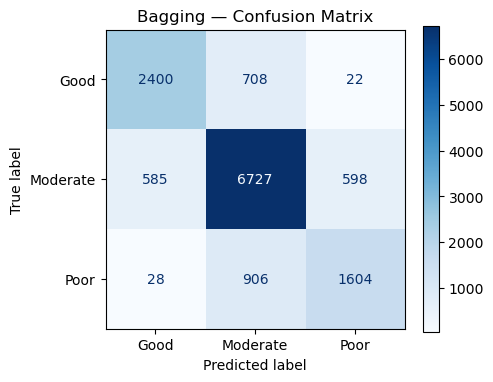

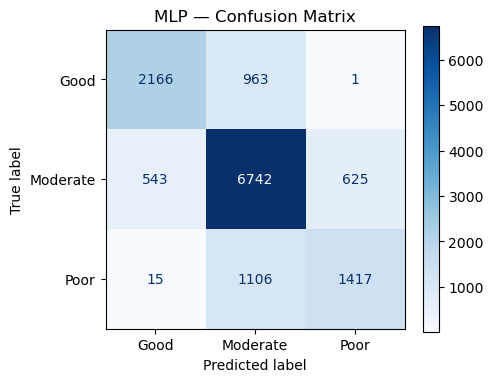

In [14]:
predictions = {
    "Random Forest": rf_pred,
    "AdaBoost": ada_pred,
    "Gradient Boosting": gb_pred,
    "Bagging": bag_pred,
    "MLP": mlp_pred
}

for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=label_encoder.classes_,
        cmap="Blues",
        ax=ax
    )
    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()


Each class is treated as the positive class against the remaining classes. The curves show discrimination performance across thresholds.

## 15. Multiclass ROC curves — One-vs-Rest

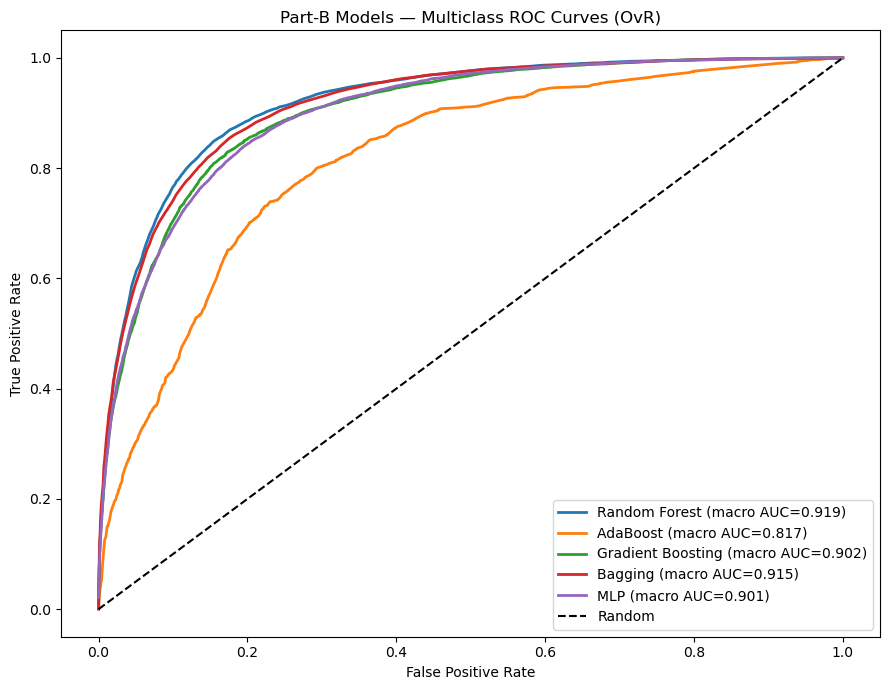

In [15]:
models = {
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "Bagging": bag_model,
    "MLP": mlp_model
}

plt.figure(figsize=(9, 7))

for name, model in models.items():
    y_score = model.predict_proba(X_test)
    fpr = {}
    tpr = {}

    for i in range(len(label_encoder.classes_)):
        binary_y = (y_test == i).astype(int)
        fpr[i], tpr[i], _ = roc_curve(binary_y, y_score[:, i])

    all_fpr = np.unique(np.concatenate([fpr[i] for i in fpr]))
    mean_tpr = np.zeros_like(all_fpr)

    for i in fpr:
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= len(fpr)
    macro_auc = auc(all_fpr, mean_tpr)

    plt.plot(all_fpr, mean_tpr, linewidth=2,
             label=f"{name} (macro AUC={macro_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Part-B Models — Multiclass ROC Curves (OvR)")
plt.legend()
plt.tight_layout()
plt.show()


GridSearchCV evaluates parameter combinations using cross-validation on training data only. The test set is kept out of model selection.

# 16. Hyperparameter tuning

Two strong Part-B models are tuned using GridSearchCV with weighted F1 and 3-fold stratified cross-validation. The test set is not used during tuning.


In [16]:
cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_grid = GridSearchCV(
    rf_tuning_pipeline,
    {
        "model__n_estimators": [150, 250],
        "model__max_depth": [None, 15],
        "model__min_samples_split": [2, 5]
    },
    scoring="f1_weighted",
    cv=cv3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best CV weighted F1:", round(rf_grid.best_score_, 4))

rf_tuned_pred = rf_grid.best_estimator_.predict(X_test)
rf_tuned_scores = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, rf_tuned_pred),
    "Precision": precision_score(y_test, rf_tuned_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, rf_tuned_pred, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, rf_tuned_pred, average="weighted", zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test,
        rf_grid.best_estimator_.predict_proba(X_test),
        multi_class="ovr",
        average="weighted"
    )
}

display(pd.DataFrame([rf_tuned_scores]))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Random Forest parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 150}
Best CV weighted F1: 0.7839


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Tuned Random Forest,0.792606,0.791412,0.792606,0.788948,0.904255


In [17]:
gb_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ))
])

gb_grid = GridSearchCV(
    gb_tuning_pipeline,
    {
        "model__n_estimators": [100, 150],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3]
    },
    scoring="f1_weighted",
    cv=cv3,
    n_jobs=-1,
    verbose=1
)

gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(gb_grid.best_params_)
print("Best CV weighted F1:", round(gb_grid.best_score_, 4))

gb_tuned_pred = gb_grid.best_estimator_.predict(X_test)
gb_tuned_scores = {
    "Model": "Tuned Gradient Boosting",
    "Accuracy": accuracy_score(y_test, gb_tuned_pred),
    "Precision": precision_score(y_test, gb_tuned_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, gb_tuned_pred, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, gb_tuned_pred, average="weighted", zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test,
        gb_grid.best_estimator_.predict_proba(X_test),
        multi_class="ovr",
        average="weighted"
    )
}

display(pd.DataFrame([gb_tuned_scores]))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Gradient Boosting parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 150}
Best CV weighted F1: 0.7641


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Tuned Gradient Boosting,0.771984,0.770159,0.771984,0.769793,0.890166


The comparison makes it clear whether tuning improved weighted F1 relative to each baseline model.

## 17. Tuning improvement

In [18]:
tuning_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Baseline Weighted F1": rf_scores["Weighted F1"],
        "Tuned Weighted F1": rf_tuned_scores["Weighted F1"],
        "Improvement": rf_tuned_scores["Weighted F1"] - rf_scores["Weighted F1"]
    },
    {
        "Model": "Gradient Boosting",
        "Baseline Weighted F1": gb_scores["Weighted F1"],
        "Tuned Weighted F1": gb_tuned_scores["Weighted F1"],
        "Improvement": gb_tuned_scores["Weighted F1"] - gb_scores["Weighted F1"]
    }
])

display(tuning_comparison.style.format({
    "Baseline Weighted F1": "{:.4f}",
    "Tuned Weighted F1": "{:.4f}",
    "Improvement": "{:+.4f}"
}))


,Model,Baseline Weighted F1,Tuned Weighted F1,Improvement
0,Random Forest,0.7919,0.7889,-0.0029
1,Gradient Boosting,0.7593,0.7698,+0.0105


Five-fold cross-validation gives a mean score and standard deviation, providing evidence of how stable the selected models are across different training folds.

## 18. Five-fold cross-validation for the two tuned models

In [19]:
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for name, model in {
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned Gradient Boosting": gb_grid.best_estimator_
}.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv5,
        scoring="f1_weighted",
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "Mean 5-Fold Weighted F1": scores.mean(),
        "Std": scores.std()
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.style.format({
    "Mean 5-Fold Weighted F1": "{:.4f}",
    "Std": "{:.4f}"
}))


,Model,Mean 5-Fold Weighted F1,Std
0,Tuned Random Forest,0.7876,0.0020
1,Tuned Gradient Boosting,0.7668,0.0013


The winner is selected from training cross-validation results, not by maximizing the test-set score.

## 19. Final Part-B model selection

The final model is selected using mean 5-fold weighted F1 on the training data. The test set is used only for the final performance report.


In [20]:
best_row = cv_results.loc[
    cv_results["Mean 5-Fold Weighted F1"].idxmax()
]

best_model_name = best_row["Model"]

if best_model_name == "Tuned Random Forest":
    final_model = rf_grid.best_estimator_
    final_scores = rf_tuned_scores
else:
    final_model = gb_grid.best_estimator_
    final_scores = gb_tuned_scores

print("Selected final Part-B model:", best_model_name)
print("\nFinal test metrics:")
for k, v in final_scores.items():
    if k != "Model":
        print(f"{k}: {v:.4f}")


Selected final Part-B model: Tuned Random Forest

Final test metrics:
Accuracy: 0.7926
Precision: 0.7914
Recall: 0.7926
Weighted F1: 0.7889
ROC-AUC: 0.9043


Tree-based feature importance offers a useful first interpretation of which input measurements contributed to the fitted model. It is not proof of causation.

## 20. Feature importance

If the selected model is tree-based, the top feature importances are displayed. This helps interpret which water-quality measurements contributed most to the model.


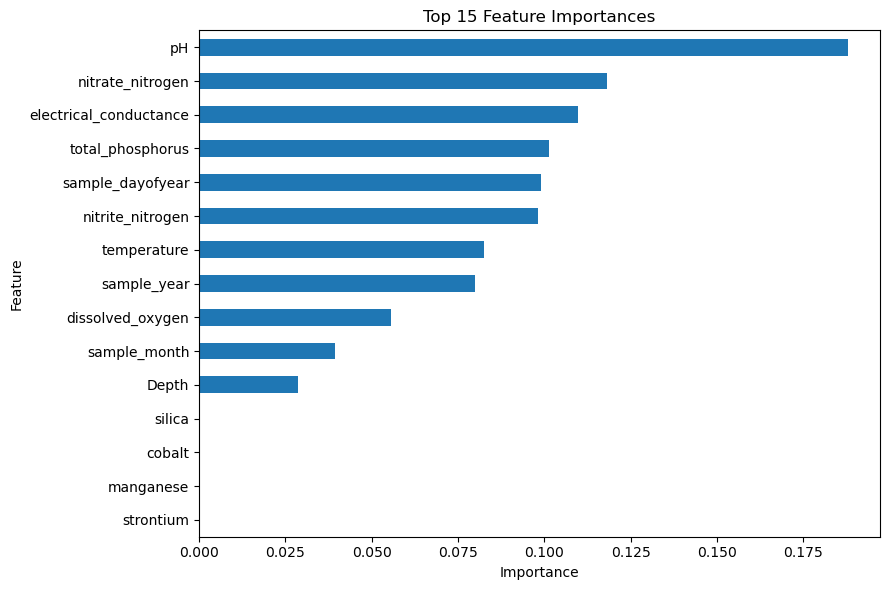

In [22]:

model_fit = final_model.named_steps["model"]

if hasattr(model_fit, "feature_importances_"):

    # Get feature names from the input data
    feature_names = X_train.columns.tolist()

    importances = model_fit.feature_importances_

    # Check whether feature names match importance values
    if len(feature_names) != len(importances):
        feature_names = [
            f"Feature_{i}" for i in range(len(importances))
        ]

    importance_series = pd.Series(
        importances,
        index=feature_names
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(9, 6))
    importance_series.sort_values().plot(kind="barh")
    plt.title("Top 15 Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

else:
    print("This model does not provide feature_importances_.")


# 21. Part-B conclusion

All five remaining Classification Part-B algorithms were implemented and compared on the same water-quality dataset.

The study reports Accuracy, Precision, Recall, weighted F1, ROC-AUC, confusion matrices, and cross-validation performance. Two strong models were tuned using GridSearchCV, and the final model is selected using training-fold cross-validation rather than the test score.


In [23]:
# 22. Save result tables

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

partB_results.to_csv(RESULTS_DIR / "classification_partB_results.csv", index=False)
tuning_comparison.to_csv(RESULTS_DIR / "classification_partB_tuning_comparison.csv", index=False)
cv_results.to_csv(RESULTS_DIR / "classification_partB_cv_results.csv", index=False)

print(f"Part-B result tables saved to: {RESULTS_DIR}")


Part-B result tables saved.
